# Notebook 3 · Interpretabilidad y análisis de errores del Modelo A
No entrena nada (**no necesita GPU**): usa el `model_A_cnn.keras` ya entrenado para responder tres preguntas:

1. **¿Dónde se equivoca?** Galería y estadísticas de las falsas sonrisas (FP) y las sonrisas perdidas (FN).
2. **¿En qué se fija el modelo?** Grad-CAM: mapas de calor de la zona de la cara que más pesó en la decisión.
3. **¿Y con caras reales de nuestra cámara?** (opcional) Evaluación con las fotos propias, para medir el *domain gap* respecto a SMILES.

**Antes de ejecutar:** sube `model_A_cnn.keras` y `A_metrics.json` como dataset de Kaggle (*Create → New Dataset*) y agrégalo como input junto con SMILES.
Para la parte opcional, sube también la carpeta `mis_fotos` (con subcarpetas `sonrie` y `no_sonrie`) y agrégala como input.

In [1]:
import os, glob, json, csv, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_curve, classification_report

SEED, IMG_SIZE = 42, 64
BASE    = "/kaggle/input/datasets/marcos03/smiles/SMILEs"
POS_DIR = f"{BASE}/positives/positives7"
NEG_DIR = f"{BASE}/negatives/negatives7"
OUT     = "/kaggle/working"
MODEL_NAME = "model_A_cnn.keras"
THRESHOLD  = None          # None -> usa el umbral guardado en A_metrics.json (o 0.5 si no está)

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

## 1. Cargar el modelo entrenado y el dataset (mismo split que en los Notebooks 1 y 2)

In [2]:
cands = glob.glob(f"/kaggle/input/**/{MODEL_NAME}", recursive=True)
assert cands, (f"No encontré {MODEL_NAME} en /kaggle/input. Sube el modelo como dataset "
               "(Create -> New Dataset) y agrégalo como input del notebook.")
MODEL_PATH = cands[0]
metrics_file = os.path.join(os.path.dirname(MODEL_PATH), "A_metrics.json")
if THRESHOLD is None:
    THRESHOLD = json.load(open(metrics_file))["umbral_recomendado"] if os.path.exists(metrics_file) else 0.5
model = keras.models.load_model(MODEL_PATH)
print("Modelo:", MODEL_PATH, "| umbral de sonrisa:", round(THRESHOLD, 2))

def list_images(folder):
    return sorted(glob.glob(os.path.join(folder, "*.jpg")))

pos_paths, neg_paths = list_images(POS_DIR), list_images(NEG_DIR)
paths = np.array(neg_paths + pos_paths)
def load_images(ps):
    return np.stack([np.array(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE))) for p in ps]).astype("float32")[..., None]
X = np.concatenate([load_images(neg_paths), load_images(pos_paths)])
y = np.concatenate([np.zeros(len(neg_paths)), np.ones(len(pos_paths))]).astype("float32")

idx = np.arange(len(y))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)
X_test, y_test, paths_test = X[idx_test], y[idx_test], paths[idx_test]
print("test:", len(y_test), "imágenes |", int(y_test.sum()), "sonrisas")

Modelo: /kaggle/input/datasets/marcos03/modeloa/model_A_cnn.keras | umbral de sonrisa: 0.34
test: 1975 imágenes | 553 sonrisas


## 2. Predicciones en test (deben coincidir con `A_metrics.json`)

In [3]:
p_test = model.predict(X_test, verbose=0).ravel()
pred = (p_test >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print("Matriz de confusión [[TN FP],[FN TP]]:", cm.tolist())
print(f"Accuracy {(pred == y_test).mean():.4f} | F1 sonríe {f1_score(y_test, pred):.4f} "
      f"| precisión {tp/(tp+fp):.3f} | recall {tp/(tp+fn):.3f}")
print("Con el A_metrics.json del entrenamiento real: accuracy 0.9322, F1 0.8820.")

correct = pred == y_test
is_fp = (pred == 1) & (y_test == 0)     # falsas sonrisas
is_fn = (pred == 0) & (y_test == 1)     # sonrisas perdidas

Matriz de confusión [[TN FP],[FN TP]]: [[1340, 82], [52, 501]]
Accuracy 0.9322 | F1 sonríe 0.8820 | precisión 0.859 | recall 0.906
Con el A_metrics.json del entrenamiento real: accuracy 0.9322, F1 0.8820.


## 3. ¿Cómo se reparten las probabilidades? ¿Por qué ese umbral?
El histograma muestra cuánto se separan las dos clases; la zona donde se superponen es donde nacen los errores.
La segunda gráfica muestra cómo cambian precisión, recall y F1 al mover el umbral (el valor elegido es el que maximizó el F1 en validación).

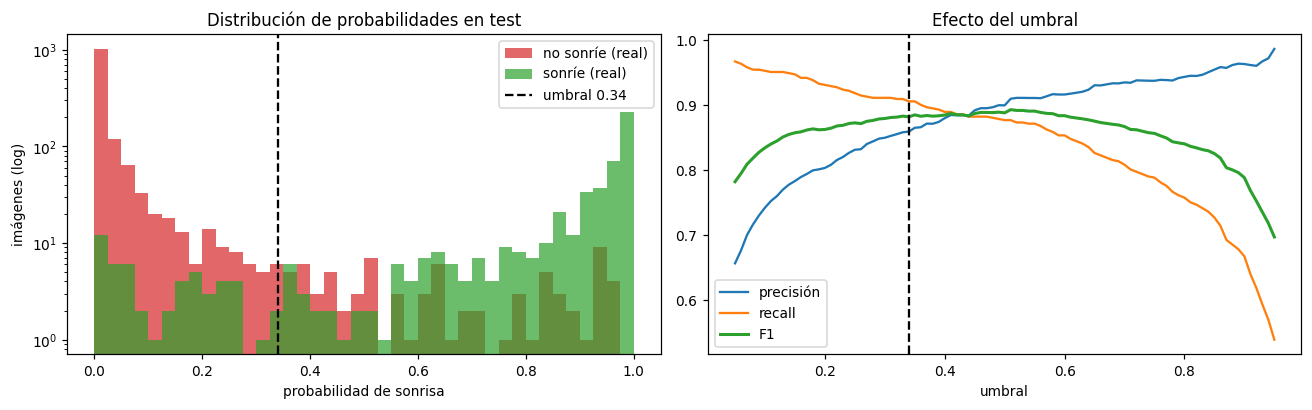

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, 1, 41)
ax[0].hist(p_test[y_test == 0], bins=bins, alpha=.7, label="no sonríe (real)", color="tab:red")
ax[0].hist(p_test[y_test == 1], bins=bins, alpha=.7, label="sonríe (real)", color="tab:green")
ax[0].axvline(THRESHOLD, color="k", ls="--", label=f"umbral {THRESHOLD:.2f}")
ax[0].set_yscale("log"); ax[0].set_xlabel("probabilidad de sonrisa"); ax[0].set_ylabel("imágenes (log)")
ax[0].set_title("Distribución de probabilidades en test"); ax[0].legend()

ths = np.arange(0.05, 0.96, 0.01)
P = [((p_test >= t) & (y_test == 1)).sum() / max(1, (p_test >= t).sum()) for t in ths]
R = [((p_test >= t) & (y_test == 1)).sum() / (y_test == 1).sum() for t in ths]
F = [f1_score(y_test, p_test >= t) for t in ths]
ax[1].plot(ths, P, label="precisión"); ax[1].plot(ths, R, label="recall"); ax[1].plot(ths, F, label="F1", lw=2)
ax[1].axvline(THRESHOLD, color="k", ls="--"); ax[1].set_xlabel("umbral"); ax[1].set_title("Efecto del umbral"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/A_umbral.png", dpi=130); plt.show()

## 4. Galería de errores
**Falsas sonrisas:** caras que NO sonríen pero el modelo marcó como sonrisa (ordenadas de la más segura a la menos).
**Sonrisas perdidas:** sonrisas reales que el modelo dejó pasar. Mira qué tienen en común (¿boca cerrada? ¿cara de lado? ¿poca luz?).

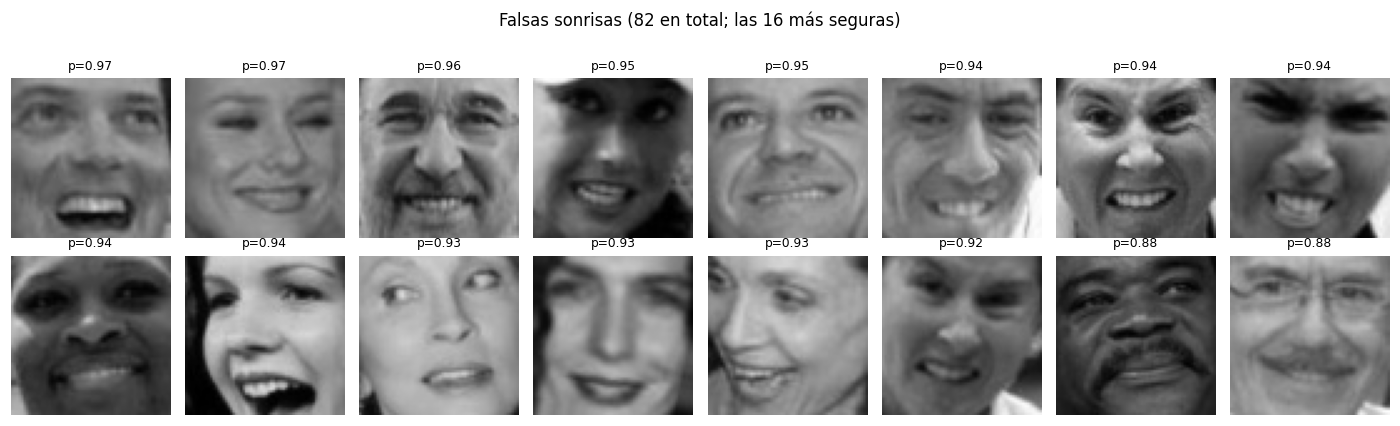

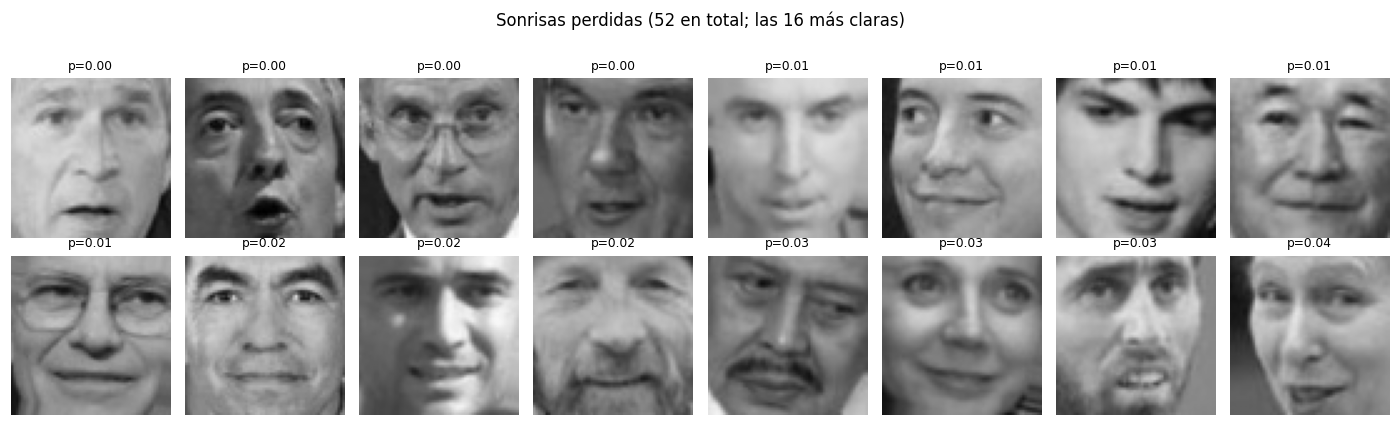

In [5]:
def gallery(idxs, title, fname, cols=8):
    idxs = list(idxs)[:cols * 2]
    rows = int(np.ceil(len(idxs) / cols)) or 1
    fig, axs = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.9), squeeze=False)
    for ax in axs.ravel(): ax.axis("off")
    for ax, i in zip(axs.ravel(), idxs):
        ax.imshow(X_test[i, ..., 0], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"p={p_test[i]:.2f}", fontsize=8)
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=130, bbox_inches="tight"); plt.show()

fp_idx = np.where(is_fp)[0]; fp_idx = fp_idx[np.argsort(-p_test[fp_idx])]
fn_idx = np.where(is_fn)[0]; fn_idx = fn_idx[np.argsort(p_test[fn_idx])]
gallery(fp_idx, f"Falsas sonrisas ({len(fp_idx)} en total; las 16 más seguras)", "A_errores_FP.png")
gallery(fn_idx, f"Sonrisas perdidas ({len(fn_idx)} en total; las 16 más claras)", "A_errores_FN.png")

In [6]:
# ¿Los errores tienen algo en común a nivel de imagen? Brillo medio y contraste (desviación estándar de grises)
bright, contrast = X_test.mean(axis=(1, 2, 3)), X_test.std(axis=(1, 2, 3))
print(f"{'grupo':28s}{'n':>6s}{'brillo medio':>15s}{'contraste':>12s}")
for name, m in (("Aciertos", correct), ("Falsas sonrisas (FP)", is_fp), ("Sonrisas perdidas (FN)", is_fn)):
    print(f"{name:28s}{int(m.sum()):6d}{bright[m].mean():15.1f}{contrast[m].mean():12.1f}")
print("\nSi un grupo de errores tiene brillo/contraste distinto al de los aciertos, es una pista de que "
      "la iluminación influye (útil para el informe y para decidir qué fotos propias faltan).")

grupo                            n   brillo medio   contraste
Aciertos                      1841          128.2        37.9
Falsas sonrisas (FP)            82          119.8        36.2
Sonrisas perdidas (FN)          52          130.8        37.1

Si un grupo de errores tiene brillo/contraste distinto al de los aciertos, es una pista de que la iluminación influye (útil para el informe y para decidir qué fotos propias faltan).


## 5. Grad-CAM: ¿en qué se fija el modelo?
Grad-CAM toma la **última capa convolucional** (mapas de 16x16), calcula cuánto aumenta la probabilidad de la clase decidida al reforzar cada mapa
(el gradiente) y los combina en un **mapa de calor**. Rojo = zona que más pesó en la decisión.
Se explica la clase que el modelo **decidió** (con el umbral actual), también en los errores: así se ve qué lo engañó.

In [7]:
last_act = [l for l in model.layers if isinstance(l, layers.Activation)][-1]   # última ReLU antes del pooling global
print("Capa usada para Grad-CAM:", last_act.name, "| salida:", last_act.output.shape)
grad_model = keras.Model(model.inputs, [last_act.output, model.output])

def gradcam(Xb, target_smile, batch=128):
    """Mapas Grad-CAM (N,64,64) en [0,1]. target_smile[i]=True explica 'sonríe', False 'no sonríe'."""
    out = []
    for i in range(0, len(Xb), batch):
        xb = tf.convert_to_tensor(Xb[i:i + batch])
        tb = tf.convert_to_tensor(np.asarray(target_smile[i:i + batch], dtype=bool))
        with tf.GradientTape() as tape:
            conv, p = grad_model(xb, training=False)
            p = p[:, 0]
            score = tf.reduce_sum(tf.where(tb, p, 1.0 - p))
        grads = tape.gradient(score, conv)                               # (B,16,16,C)
        w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)           # importancia de cada canal
        cam = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[..., None]   # (B,16,16,1)
        cam = tf.image.resize(cam, (IMG_SIZE, IMG_SIZE), method="bicubic")[..., 0].numpy()
        cam = cam / (cam.reshape(len(cam), -1).max(axis=1)[:, None, None] + 1e-8)
        out.append(np.clip(cam, 0, 1))
    return np.concatenate(out)

pred_smile = pred.astype(bool)
cam_test = gradcam(X_test, pred_smile)
print("Mapas calculados:", cam_test.shape)

Capa usada para Grad-CAM: activation_5 | salida: (None, 16, 16, 128)
Mapas calculados: (1975, 64, 64)


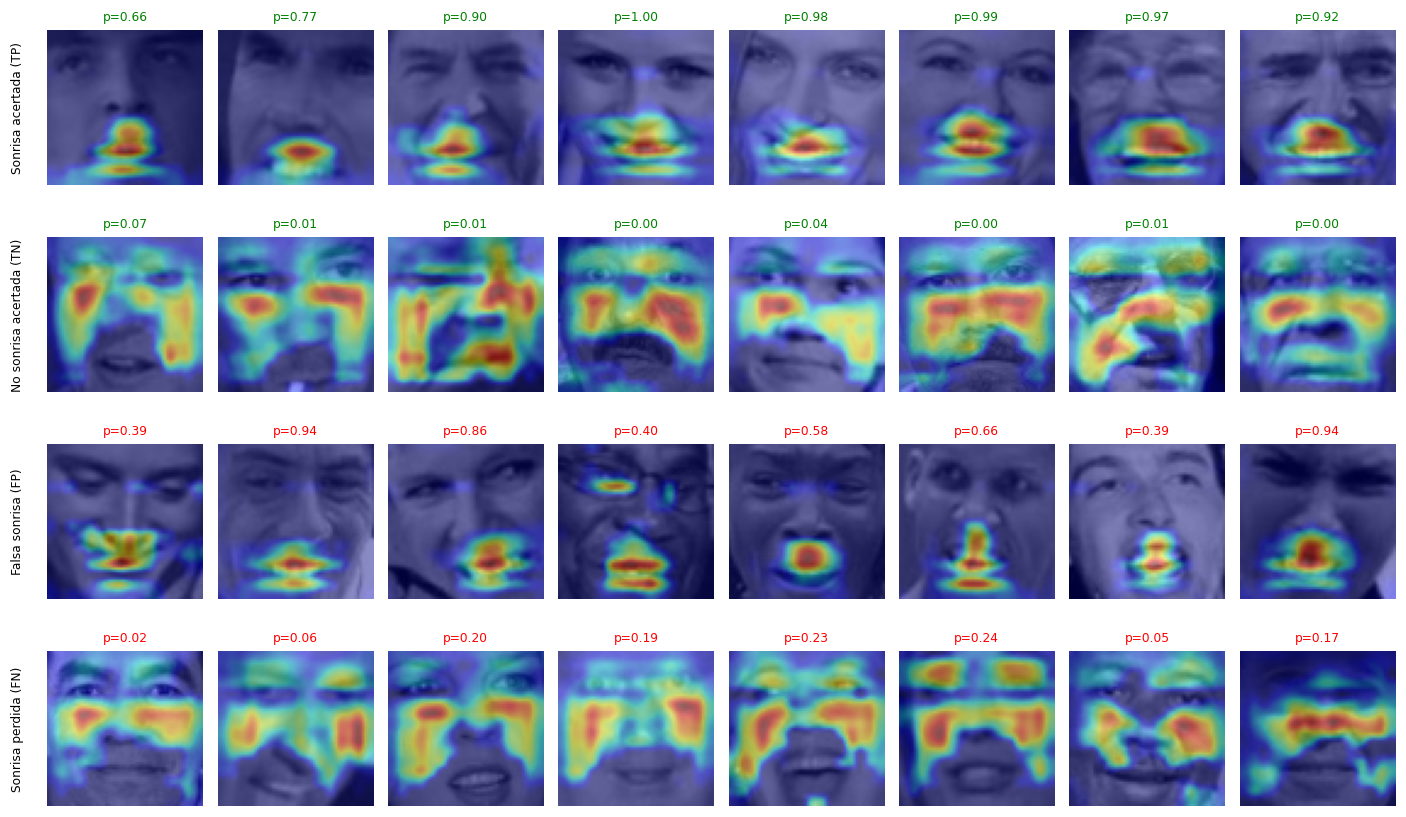

In [8]:
def cam_gallery(groups, fname, n=8):
    rows = len(groups)
    fig, axs = plt.subplots(rows, n, figsize=(n * 1.6, rows * 1.9), squeeze=False)
    for ax in axs.ravel(): ax.axis("off")
    rng = np.random.default_rng(SEED)
    for r, (title, idxs, color) in enumerate(groups):
        idxs = np.asarray(idxs)
        sel = rng.choice(idxs, min(n, len(idxs)), replace=False) if len(idxs) else []
        for c, i in enumerate(sel):
            ax = axs[r, c]
            ax.imshow(X_test[i, ..., 0], cmap="gray", vmin=0, vmax=255)
            ax.imshow(cam_test[i], cmap="jet", alpha=0.45, vmin=0, vmax=1)
            ax.set_title(f"p={p_test[i]:.2f}", fontsize=8, color=color)
        axs[r, 0].text(-0.15, 0.5, title, transform=axs[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=130, bbox_inches="tight"); plt.show()

tp_idx = np.where((pred == 1) & (y_test == 1))[0]
tn_idx = np.where((pred == 0) & (y_test == 0))[0]
cam_gallery([("Sonrisa acertada (TP)", tp_idx, "green"), ("No sonrisa acertada (TN)", tn_idx, "green"),
             ("Falsa sonrisa (FP)", fp_idx, "red"), ("Sonrisa perdida (FN)", fn_idx, "red")],
            "A_gradcam_galeria.png")

### Mapa de atención promedio
Promedio de los Grad-CAM de todas las sonrisas y no-sonrisas acertadas: muestra **dónde mira el modelo en general**.

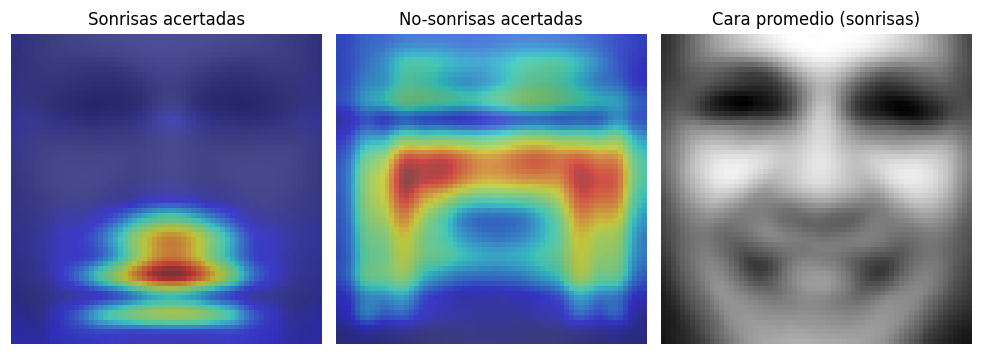

atención en la mitad inferior - sonrisas acertadas (TP)     : 97 %
atención en la mitad inferior - no-sonrisas acertadas (TN)  : 44 %
atención en la mitad inferior - falsas sonrisas (FP)        : 95 %
atención en la mitad inferior - sonrisas perdidas (FN)      : 35 %

Interpretación orientativa: si en las sonrisas acertadas la atención se concentra abajo (boca) y en los errores se dispersa hacia otras zonas, el modelo se fija en el lugar correcto cuando acierta.


In [9]:
mean_tp, mean_tn = cam_test[tp_idx].mean(axis=0), cam_test[tn_idx].mean(axis=0)
fig, axs = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, (m, t) in zip(axs[:2], ((mean_tp, "Sonrisas acertadas"), (mean_tn, "No-sonrisas acertadas"))):
    ax.imshow(np.mean(X_test, axis=0)[..., 0], cmap="gray", vmin=0, vmax=255)
    im = ax.imshow(m, cmap="jet", alpha=0.55); ax.set_title(t); ax.axis("off")
axs[2].imshow(np.mean(X_test[y_test == 1], axis=0)[..., 0], cmap="gray"); axs[2].set_title("Cara promedio (sonrisas)"); axs[2].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/A_gradcam_promedio.png", dpi=130); plt.show()

# ¿Qué fracción de la atención cae en la mitad inferior de la imagen (donde suele estar la boca)?
def frac_lower(cams): return float(cams[:, IMG_SIZE // 2:, :].sum() / (cams.sum() + 1e-8))
frac = {"sonrisas acertadas (TP)": frac_lower(cam_test[tp_idx]), "no-sonrisas acertadas (TN)": frac_lower(cam_test[tn_idx]),
        "falsas sonrisas (FP)": frac_lower(cam_test[fp_idx]) if len(fp_idx) else None,
        "sonrisas perdidas (FN)": frac_lower(cam_test[fn_idx]) if len(fn_idx) else None}
for k, v in frac.items():
    if v is not None: print(f"atención en la mitad inferior - {k:28s}: {v*100:.0f} %")
print("\nInterpretación orientativa: si en las sonrisas acertadas la atención se concentra abajo (boca) y en los "
      "errores se dispersa hacia otras zonas, el modelo se fija en el lugar correcto cuando acierta.")

## 6. (Opcional) Evaluación con fotos propias — medir el *domain gap*
Si agregaste la carpeta `mis_fotos` (subcarpetas `sonrie` y `no_sonrie`), el modelo se evalúa con esas imágenes **sin haberlas visto nunca**.
La diferencia con el test de SMILES es el efecto de pasar de caras de laboratorio a caras de su cámara. Si no está la carpeta, esta sección se omite.

In [10]:
EXT = (".jpg", ".jpeg", ".png", ".bmp")
own_pos = sorted(p for p in glob.glob("/kaggle/input/**/sonrie/*", recursive=True) if p.lower().endswith(EXT))
own_neg = sorted(p for p in glob.glob("/kaggle/input/**/no_sonrie/*", recursive=True) if p.lower().endswith(EXT))
own_summary = None
if len(own_pos) >= 5 and len(own_neg) >= 5:
    Xo = load_images(own_neg + own_pos)
    yo = np.concatenate([np.zeros(len(own_neg)), np.ones(len(own_pos))])
    po = model.predict(Xo, verbose=0).ravel(); predo = (po >= THRESHOLD).astype(int)
    cmo = confusion_matrix(yo, predo); tno, fpo, fno, tpo = cmo.ravel()
    own_summary = dict(n=len(yo), n_sonrie=len(own_pos), n_no_sonrie=len(own_neg), accuracy=float((predo == yo).mean()),
                       f1=float(f1_score(yo, predo)), matriz=cmo.tolist())
    print(f"Fotos propias: {len(own_pos)} sonríe + {len(own_neg)} no sonríe")
    print(classification_report(yo, predo, target_names=["no sonríe", "sonríe"], digits=3, zero_division=0))
    print(f"{'':22s}{'SMILES (test)':>15s}{'Fotos propias':>15s}")
    print(f"{'Accuracy':22s}{(pred == y_test).mean():15.3f}{own_summary['accuracy']:15.3f}")
    print(f"{'F1 sonríe':22s}{f1_score(y_test, pred):15.3f}{own_summary['f1']:15.3f}")

    cam_o = gradcam(Xo, predo.astype(bool))
    wrong = np.where(predo != yo)[0]; right = np.where(predo == yo)[0]
    rng = np.random.default_rng(SEED)
    sel = list(rng.choice(right, min(8, len(right)), replace=False)) + list(wrong[:8])
    fig, axs = plt.subplots(2, 8, figsize=(13, 3.8))
    for ax in axs.ravel(): ax.axis("off")
    for ax, i in zip(axs.ravel(), sel):
        ax.imshow(Xo[i, ..., 0], cmap="gray", vmin=0, vmax=255); ax.imshow(cam_o[i], cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax.set_title(f"real={'sonríe' if yo[i] else 'no'} p={po[i]:.2f}", fontsize=7, color="green" if predo[i] == yo[i] else "red")
    plt.suptitle("Fotos propias: aciertos (arriba, verde) y errores (abajo, rojo)"); plt.tight_layout()
    plt.savefig(f"{OUT}/A_fotos_propias.png", dpi=130, bbox_inches="tight"); plt.show()
else:
    print("No encontré la carpeta mis_fotos (sonrie / no_sonrie) en /kaggle/input: se omite esta sección.")

No encontré la carpeta mis_fotos (sonrie / no_sonrie) en /kaggle/input: se omite esta sección.


## 7. Guardar resultados

In [11]:
with open(f"{OUT}/A_errores.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["archivo", "real", "prob_sonrisa", "tipo_error"])
    for i in np.where(~correct)[0]:
        w.writerow([os.path.basename(paths_test[i]), int(y_test[i]), round(float(p_test[i]), 4), "FP" if is_fp[i] else "FN"])

summary = dict(umbral=float(THRESHOLD), test_accuracy=float((pred == y_test).mean()), test_f1=float(f1_score(y_test, pred)),
               matriz_confusion=cm.tolist(), atencion_mitad_inferior=frac,
               brillo_medio={k: float(bright[m].mean()) for k, m in (("aciertos", correct), ("FP", is_fp), ("FN", is_fn)) if m.any()},
               fotos_propias=own_summary)
json.dump(summary, open(f"{OUT}/A_interpretabilidad.json", "w"), indent=2, ensure_ascii=False)
print("Archivos en /kaggle/working:", sorted(os.listdir(OUT)))

Archivos en /kaggle/working: ['A_errores.csv', 'A_errores_FN.png', 'A_errores_FP.png', 'A_gradcam_galeria.png', 'A_gradcam_promedio.png', 'A_interpretabilidad.json', 'A_umbral.png', '__notebook__.ipynb']
